# BAFAD Week 2 — Exercise 1: Time-Series Manipulation & Data Poisoning

**Week:** 2 · Oct 5–11, 2026  
**Your name:** *(fill in)*  
**Commit when done:** `feat: download and parse raw time-series streams`

---

## Overview

This exercise introduces the two foundational data operations used throughout the BAFAD project:
generating a synthetic multivariate sensor stream and injecting a localized noise event that simulates
active signal jamming. The math here is simple — the goal is to get comfortable manipulating
numpy arrays by index window and to visualize what a sensor anomaly looks like before any model sees it.

All three sections of this notebook connect directly to the real data pipeline you will build in Weeks 3–4.

## Section 1: Setup & Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f'NumPy version: {np.__version__}')
print('Imports successful.')

NumPy version: 2.1.3
Imports successful.


## Section 2: Generate the Baseline Sensor Stream

Run the cell below as-is. It creates a clean 3-channel sensor stream with slight Gaussian noise.
Read the code carefully — you will write a similar generator in Week 3 for real data.

In [2]:
def generate_sensor_stream(samples=1000, features=3, seed=42):
    """Generates synthetic multivariate time-series baseline sensor data."""
    np.random.seed(seed)
    t = np.linspace(0, 50, samples)
    stream = np.zeros((samples, features))
    for f in range(features):
        stream[:, f] = np.sin(t * (f + 1)) + np.random.normal(0, 0.05, samples)
    return stream

clean_stream = generate_sensor_stream(samples=1000, features=3)
print(f'Clean stream shape: {clean_stream.shape}')   # Expected: (1000, 3)
print(f'Value range: [{clean_stream.min():.3f}, {clean_stream.max():.3f}]')
assert clean_stream.shape == (1000, 3), 'Shape mismatch'
print('Shape assertion passed.')

Clean stream shape: (1000, 3)
Value range: [-1.126, 1.157]
Shape assertion passed.


## Section 3: Implement `inject_tactical_jamming()`

**Your task:** Complete the function below by filling in the two TODO lines.

The function must:
1. Create a copy of `raw_data` (do not modify the original)
2. Generate a Gaussian noise array of shape `(end_idx - start_idx, number_of_features)` using `np.random.normal(0, variance, size=...)`
3. Add the noise to the correct index slice of the copied array
4. Return the modified copy

**Hint:** Use numpy index slicing — `array[start:end, :]` selects all columns for rows `start` through `end-1`.

In [3]:
def inject_tactical_jamming(raw_data, start_idx=400, end_idx=550, variance=2.5):
    """
    Injects high-variance Gaussian noise into a localized index window
    to simulate active tactical signal jamming.

    Parameters
    ----------
    raw_data   : np.ndarray, shape (T, F)
    start_idx  : int — first row of the jamming window (inclusive)
    end_idx    : int — last row of the jamming window (exclusive)
    variance   : float — std dev of injected Gaussian noise

    Returns
    -------
    poisoned_data : np.ndarray, shape (T, F) — copy with noise injected
    """
    poisoned_data = raw_data.copy()

    # TODO 1: Generate a Gaussian noise array of the correct shape
    # Shape must be (end_idx - start_idx, poisoned_data.shape[1])
    noise = np.random.normal(0, variance, size=(end_idx - start_idx, poisoned_data.shape[1]))

    # TODO 2: Add the noise to the correct index window of poisoned_data
    poisoned_data[start_idx:end_idx, :] += noise

    return poisoned_data


# Apply jamming and run verification checks
jammed_stream = inject_tactical_jamming(clean_stream, start_idx=400, end_idx=550, variance=2.5)

assert jammed_stream.shape == clean_stream.shape, 'Output shape must match input shape'
assert not np.array_equal(jammed_stream[400:550], clean_stream[400:550]), \
    'Jamming window should differ from clean stream'
assert np.array_equal(jammed_stream[:400], clean_stream[:400]), \
    'Rows before window must be unchanged'
assert np.array_equal(jammed_stream[550:], clean_stream[550:]), \
    'Rows after window must be unchanged'

clean_mag  = np.abs(clean_stream[400:550]).mean()
jammed_mag = np.abs(jammed_stream[400:550]).mean()
print(f'Clean window mean |value|:  {clean_mag:.4f}')
print(f'Jammed window mean |value|: {jammed_mag:.4f}')
assert jammed_mag > clean_mag, 'Jammed window should have higher magnitude than clean'
print('All assertions passed.')

Clean window mean |value|:  0.6470
Jammed window mean |value|: 2.1654
All assertions passed.


## Section 4: Visualize Clean vs. Jammed Signal

**Your task:** Complete the plot scaffold below.

Requirements:
- Two vertically stacked subplots sharing the x-axis
- Top panel: Sensor 1 from `clean_stream` (blue)
- Bottom panel: Sensor 1 from `jammed_stream` (red)
- Both panels: a shaded region marking the jamming window (rows 400–549)
- Both panels: a legend, y-label, and title
- Save the figure as `week02_exercise1_plot.png`

Refer to the `plot_sensor_stream` function in the Week 2 lecture notes for guidance.

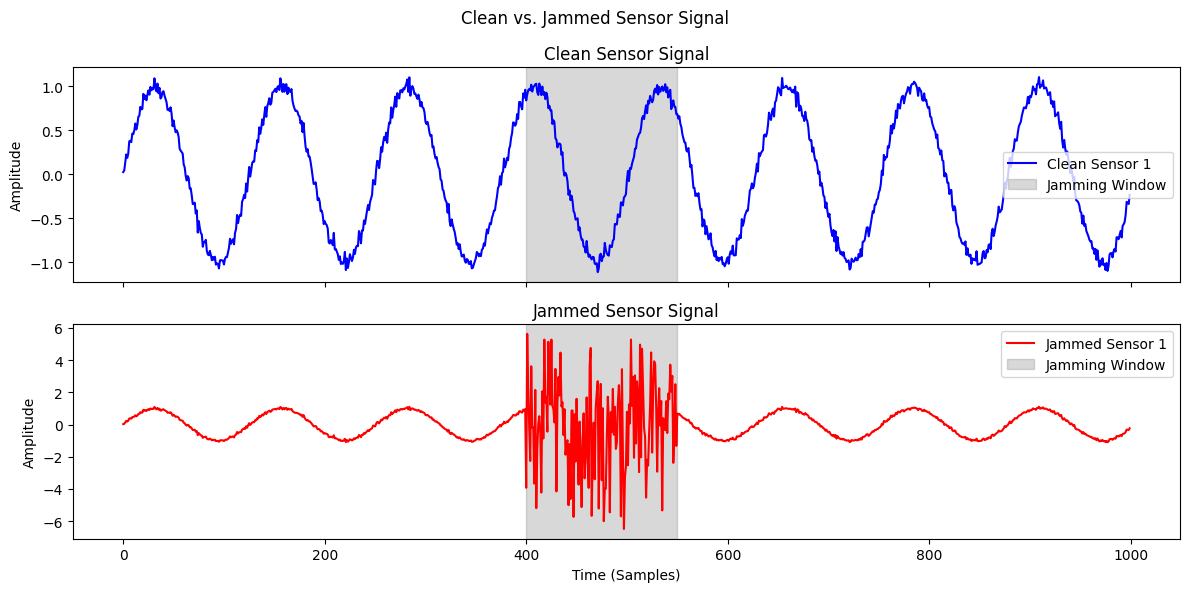

Plot saved.


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
t = np.arange(1000)

# TODO: Plot clean stream on axes[0]
axes[0].plot(t, clean_stream[:, 0], color='blue', label='Clean Sensor 1')
axes[0].axvspan(400, 550, color='gray', alpha=0.3, label='Jamming Window')
axes[0].set_title('Clean Sensor Signal')
axes[0].set_ylabel('Amplitude')
axes[0].legend()

# TODO: Plot jammed stream on axes[1]
axes[1].plot(t, jammed_stream[:, 0], color='red', label='Jammed Sensor 1')
axes[1].axvspan(400, 550, color='gray', alpha=0.3, label='Jamming Window')
axes[1].set_title('Jammed Sensor Signal')
axes[1].set_ylabel('Amplitude')
axes[1].set_xlabel('Time (Samples)')
axes[1].legend()

# TODO: Add overall figure title and save
fig.suptitle('Clean vs. Jammed Sensor Signal')

plt.tight_layout()
plt.savefig('week02_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved.')

## Section 5: Interpretation Questions

Answer each question in the cell below by replacing the placeholder text. Write 2–4 sentences per answer.

**Q1.** What happens to the signal in the jamming window compared to the clean stream? Describe both visually (what you see in the plot) and numerically (use the values printed by the assertion cell).

> *When looking at the graph, I noticed that the clean signal has a pretty consistent pattern, while the jammed signal is all over the place with much bigger spikes. The clean window had an average absolute value of 0.6470, while the jammed window increased to 2.1654. This shows how much the added noise changes the signal compared to what it normally looks like.*

**Q2.** The function uses `raw_data.copy()` before modifying the array. What would happen if you modified `raw_data` directly instead? Why does this matter for the rest of the pipeline?

> *If I changed the raw data directly, I would basically be changing the original data too. This would be a problem because I wouldn't have the clean version to compare it to anymore. Making a copy allows me to add noise and experiment with the data without messing up the original, which is important when trying to figure out what is normal and what is an anomaly.*

**Q3.** If you increased `variance` from 2.5 to 10.0, would the anomaly detection task become easier or harder? Explain in terms of reconstruction error and threshold calibration.

> *I think increasing the variance from 2.5 to 10.0 would make the anomalies easier to detect because the noise would be much stronger and more noticeable. The reconstruction error would probably be higher since the jammed signal would be further away from what the model considers normal. This could make it easier to tell the difference between normal and abnormal data, but we would still need to make sure the detection threshold is set correctly so normal data doesn't accidentally get flagged.*

## Section 6: Git Commit

When all assertions pass and the plot renders, run the following in a Colab terminal cell:

```bash
git add week02/BAFAD_Week02_Exercise1.ipynb
git commit -m "feat: download and parse raw time-series streams"
git push origin main
```

Bring your GitHub commit link and the saved plot to the Week 2 check-in.